In [2]:
import math
import numpy as np
import matplotlib.pyplot as plt
from graphviz import Digraph
import random
%matplotlib inline

In [22]:
class Value:
    def __init__(self, x, parent=None, label='' ):
        if parent == None:
            parent = set()
        self._prev = parent
        self.label = label
        self.data = x
        self._op = ""
        self._backward = lambda : None
        self.grad = 0.0

        




        


    def backward(self):
        self.grad = 1.0
        topo = []
        visited = set()

        def sort(child):
            if child not in visited:
                visited.add(child)
                for k in child._prev:
                    sort(k)
                topo.append(child)


        sort(self)
        
        for child in reversed(topo):
            child._backward()

    def zero_grad(self):
        topo = []
        visited = set()

        def sort(child):
            if child not in visited:
                visited.add(child)
                for k in child._prev:
                    sort(k)
                topo.append(child)


        sort(self)
        
        for child in reversed(topo):
            child.grad = 0.0
    def __repr__(self):
        return f'Value({self.data})'


    def __add__(self, other):
        other = other if isinstance(other, Value) else Value(other)
        out = Value(self.data + other.data, (self, other))

        def _backward():
            self.grad += out.grad * 1
            other.grad += out.grad * 1

        out._backward = _backward
        out._op = '+'
        return out

    def __radd__(self, other):
        other = other if isinstance(other, Value) else Value(other)
        out = Value(self.data + other.data, (self, other))

        def _backward():
            self.grad += out.grad * 1
            other.grad += out.grad * 1

        out._backward = _backward
                
        out._op = '+'
        return out

    def __neg__(self):
        return (-1)*self


    def relu(self):
        out = Value(self.data if self.data > 0 else 0, (self,))
        out._op = 'relu'

        def _backward():
            self.grad += out.grad * (out.data > 0)

        out._backward = _backward

        return out

    def __sub__(self, other):
        return self + (-other)

    def __rsub__(self, other):
            return (-self) + other

    def __mul__(self, other):
        other = other if isinstance(other, Value) else Value(other)
        out = Value(self.data * other.data, (self, other))
        def _backward():
            self.grad += out.grad * other.data
            other.grad += out.grad * self.data

        out._backward = _backward
        out._op = '*'
        return out

    def __truediv__(self, other):
        return self*(other**-1)


    def __rtruediv__(self, other):
        return other*(self**-1)

    def tanh(self):
        out = Value((math.exp(2*self.data) - 1)/(math.exp(2*self.data) + 1), (self,))
        out._op = 'tanh'

        def _backward():
            self.grad += out.grad * (1-(out.data**2))

        out._backward = _backward

        return out
    
    def exp(self):
        out = Value(math.exp(self.data), (self,))
        out._op = 'exp'

        def _backward():
            self.grad += out.grad * out.data

        out._backward = _backward

        return out


    def __rmul__(self, other):
        other = other if isinstance(other, Value) else Value(other)
        out = Value(self.data * other.data, (self, other))
        def _backward():
            self.grad += out.grad * other.data
            other.grad += out.grad * self.data

        out._backward = _backward
        out._op = '*'
        return out



    def __pow__(self, other):
        assert isinstance(other, (int, float)), "we are currently using float or int to calculate pow"
        out = Value(self.data**other, (self,))
        
        def _backward():
            self.grad += out.grad * other * self.data**(other-1)

        out._backward = _backward
        out._op = f'**{other}'
        return out



def trace(root):
    nodes, edges = set(), set()
    def build(v):
        if v not in nodes:
            nodes.add(v)
            for child in v._prev:
                edges.add((child, v))
                build(child)
    build(root)
    return nodes, edges

def draw_dot(root, format='svg', rankdir='LR'):
    """
    format: png | svg | ...
    rankdir: TB (top to bottom graph) | LR (left to right)
    """
    assert rankdir in ['LR', 'TB']
    nodes, edges = trace(root)
    dot = Digraph(format=format, graph_attr={'rankdir': rankdir}) #, node_attr={'rankdir': 'TB'})
    
    for n in nodes:
        dot.node(name=str(id(n)), label = "{ %s | data %.4f | grad %.4f }" % (n.label, n.data, n.grad), shape='record')
        if n._op:
            dot.node(name=str(id(n)) + n._op, label=n._op)
            dot.edge(str(id(n)) + n._op, str(id(n)))
    
    for n1, n2 in edges:
        dot.edge(str(id(n1)), str(id(n2)) + n2._op)
    
    return dot




In [36]:
class Neuron:
    def __init__(self, nin):
        self.nin = nin
        self.w = []
        self.b = Value(random.uniform(-1,1))
        for i in range(nin):
            self.w.append(Value(random.uniform(-1, 1)))

    def __call__(self, x, activation=True):
        if (activation):
            return sum((wi * xi for (wi, xi) in zip(self.w, x)), self.b).relu()
        else:
            return sum((wi * xi for (wi, xi) in zip(self.w, x)), self.b)
        

    def parameters(self):
        return self.w + [self.b]




class Layer:
    def __init__(self, nin, nout):
        self.nin = nin
        self.nout = nout
        self.neurons = []
        for i in range(self.nout):
            self.neurons.append(Neuron(self.nin))

    def __call__(self, x, activation=True, last=False):
        if (last):
            if (activation):
                return self.neurons[0](x)
            else:
                return self.neurons[0](x, False)

        else:
            if(activation):
                return [neuron(x) for neuron in self.neurons]
            else:
                return [neuron(x, False) for neuron in self.neurons] 


    def parameters(self):
        return [p for neuron in self.neurons for p in neuron.parameters()]


class MLP:
    def __init__(self, nin, nouts):
        self.layers = []
        temp = [nin] + nouts
        for i in range(len(temp) - 1):
            self.layers.append(Layer(temp[i], temp[i+1]))


    def __call__(self, x):
        for i in range(len(self.layers) - 1):
            x = self.layers[i](x)
        x = self.layers[len(self.layers)-1](x, False, True)
        return x

    def parameters(self):
        return [p for layer in self.layers for p in layer.parameters()]


        

In [45]:
model = MLP(3, [4, 4, 1])
x = [2.0, 3.0, -1.0]
print(model(x))    
print(len(model.parameters()))

Value(-0.8654092987182465)
41


In [56]:
import torch

x1 = torch.tensor(2.0, dtype=torch.float64, requires_grad=True)
x2 = torch.tensor(0.0, dtype=torch.float64, requires_grad=True)
w1 = torch.tensor(-3.0, dtype=torch.float64, requires_grad=True)
w2 = torch.tensor(1.0, dtype=torch.float64, requires_grad=True)
b  = torch.tensor(6.8813735870195432, dtype=torch.float64, requires_grad=True)

n = x1*w1 + x2*w2 + b
o = torch.tanh(n)

o.backward()

print(o.item())
print(x1.grad.item(), w1.grad.item(), x2.grad.item(), w2.grad.item())







0.7071067811865476
-1.4999999999999996 0.9999999999999998 0.4999999999999999 0.0


In [55]:
xs = [
    [2.0, 3.0, -1.0],
    [3.0, -1.0, 0.5],
    [0.5, 1.0, 1.0],
    [1.0, 1.0, -1.0],
]
ys = [1.0, -1.0, -1.0, 1.0]

model = MLP(3, [4, 4, 1])

for i in range(100):
    ypred = [model(xi) for xi in xs]
    loss = sum((yp-yi)**2 for (yp, yi) in zip(ypred, ys))
    print(i, loss.data)
    loss.backward()
    for node in model.parameters():
        node.data += -0.1 * node.grad
    loss.zero_grad()



[model(xi) for xi in xs]

0 5.052501350456555
1 2.406157892710232
2 1.9128588677579499
3 0.7161372011309413
4 0.24621772854927318
5 0.14134197393250178
6 0.10872939069991393
7 0.08766424828836354
8 0.07304553077492262
9 0.062366101621834924
10 0.05425575007534518
11 0.04790647955858896
12 0.042813020919629026
13 0.038644239782907146
14 0.035174632031560155
15 0.03224563390101796
16 0.02974268812439925
17 0.02758108442333769
18 0.02569690765446724
19 0.024041074321881392
20 0.02257529906368566
21 0.02126930255334381
22 0.020098838554661953
23 0.019044273919169234
24 0.018089549504461677
25 0.01722140836711202
26 0.016428814632994945
27 0.01570251047348274
28 0.015034674503694848
29 0.014418655614549565
30 0.013848763569416826
31 0.013320102780666008
32 0.012828439263034688
33 0.012370093316437994
34 0.011941852336422308
35 0.011540899498180605
36 0.011164755054495764
37 0.010811227728936635
38 0.010478374242784572
39 0.010164465436719705
40 0.009867957771364275
41 0.009587469239680214
42 0.009321758917356489
43 

[Value(0.9596287462150878),
 Value(-0.9906062429367686),
 Value(-0.9650932345558889),
 Value(0.977295842169009)]

_IncompleteInputError: incomplete input (2920863220.py, line 1)

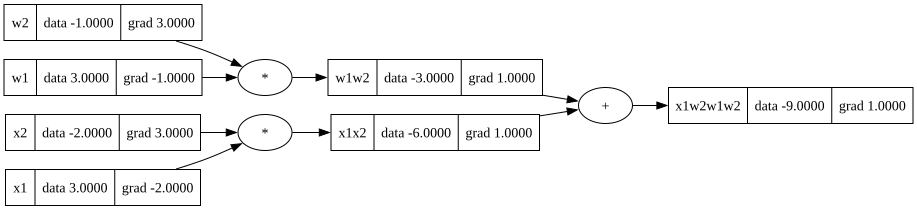

In [37]:
x1 = Value(3.0); x1.label = 'x1'
x2 = Value(-2.0); x2.label = 'x2'
x1x2 = x1 * x2; x1x2.label = 'x1x2'
w1 = Value(3.0); w1.label = 'w1'
w2 = Value(-1.0); w2.label = 'w2'
w1w2 = w1 * w2; w1w2.label = 'w1w2'

x1x2w1w2 = x1x2 + w1w2; x1x2w1w2.label = 'x1w2w1w2'
x1x2w1w2.backward()


draw_dot(x1x2w1w2)

In [27]:
a = Value(3.0)


3 - a

Value(0.0)

In [38]:
x1 = Value(2.0, label='x1')
x2 = Value(0.0, label='x2')

w1 = Value(-3.0, label='w1')
w2 = Value(1.0, label='w2')

b = Value(6.8813735870195432, label='b')

x1w1 = x1 * w1; x1w1.label = 'x1w1'
x2w2 = x2 * w2; x2w2.label = 'x2w2'
x1w1x2w2 = x1w1 + x2w2; x1w1x2w2.label = 'x1w1 + x2w2'
n = x1w1x2w2 + b; n.label = 'n'

o = n.tanh(); o.label = 'o'
o.grad = 1.0
o.backward()

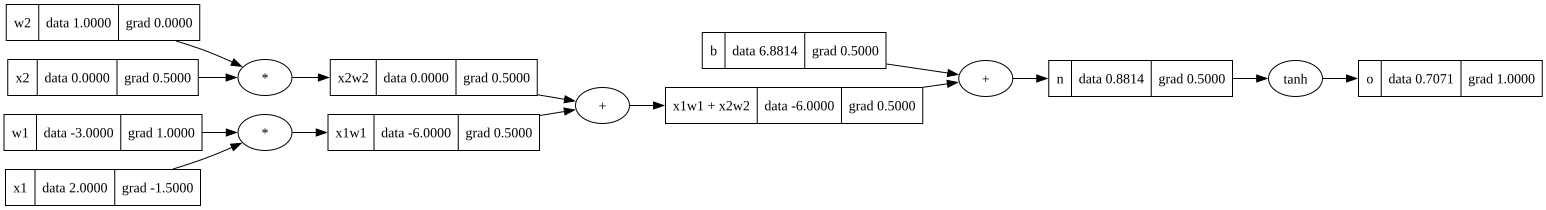

In [39]:
draw_dot(o)

In [ ]:
xs = [-1 + 0.04 * i for i in range(50)]
ys = [math.sin((-1 + 0.04 * i) * 2 * math.pi) for i in range(50)]

model = MLP(1, [8, 1])
for n in model.layers[0].neurons:
    w = random.choice([-1, 1]) * random.uniform(1, 3)   # 기울기: 크기 1~3, 부호 무작위
    c = random.uniform(-1, 1)                            # 꺾이는 점 위치
    n.w[0].data = w
    n.b.data = -w * c                                    
for i in range(2000):
    ypred = [model([xi]) for xi in xs]
    loss = sum((yp-yi)**2 for (yp, yi) in zip(ypred, ys)) / 50
    print(i, loss.data)
    loss.backward()
    for node in model.parameters():
        node.data += -0.02 * node.grad
    loss.zero_grad()



xs = np.linspace(-1, 1, 400)

plt.plot(xs, np.sin(2*np.pi*xs), label='true', color='black', linestyle='--')
plt.plot(xs, [model([x]).data for x in xs], label='model', color='tab:blue')

plt.legend()
plt.show()

0 10.879330634082555
1 6.008926594972664
2 3.635647424252067
3 2.3208877864300628
4 1.553964126446166
5 1.0945709725702366
6 0.8158687880221197
7 0.6453472183531099
8 0.5405105551421869
9 0.47585249213385844
10 0.4358756352362409
